# CE 477 – Data Science: Assignment #2 (Part 2: Regression)

**Institution:** Izmir University of Economics  
**Department:** Department of Computer Engineering  
**Dataset:** AFAD Seismic Activity Catalog (Preprocessed Dataset, $N = 153,439$)

---

## 1. Problem Formulation and Target Attribute Selection

In accordance with **Assignment #2 – Task 2 (Regression)**, two different numeric attributes are modelled as independent regression targets:

| Target | Physical meaning | Why it was selected |
|---|---|---|
| `magnitude` | Seismic energy release (M) | Central quantity of hazard assessment; continuous, strictly positive (MAPE well-defined). |
| `depth` | Hypocentral focal depth (km) | Separates shallow crustal ruptures from deep subduction events; independent physical dimension (Assignment #1 PCA: PC2). |

For each target, three regressors are trained on a **70% training / 30% testing** split (`random_state=42`):
1. **Linear Regression** – parametric, interpretable baseline.
2. **Random Forest Regressor** – bagged ensemble of decision trees capturing non-linear spatial patterns.
3. **HistGradientBoosting Regressor** – boosted tree ensemble.

Performance is compared using **RMSE**, **MAPE** and the **Pearson correlation coefficient (r)** (MAE and $R^2$ are reported additionally).

**Leakage control:** all target-derived columns (`*_norm`, `*_std`, `magnitude_class`, `depth_class`, `is_major`, `PCA1–3`) are excluded from the feature space. Province encodings and the `StandardScaler` are fitted on the training split only.

In [1]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/mplconfig"
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300

RANDOM_STATE = 42
TEST_SIZE = 0.30
PLOT_SAMPLE = 6000  # points drawn in scatter plots (metrics always use the full test set)

WORKSPACE = os.path.abspath("..")
DATA_PATH = os.path.join(WORKSPACE, "data", "afad_earthquake_data_preprocessed.csv")
FIG_DIR = os.path.join(WORKSPACE, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

MODEL_COLORS = {
    "Linear Regression": "#4C72B0",
    "Random Forest": "#55A868",
    "Gradient Boosting": "#C44E52",
}

## 2. Data Loading and Shared Feature Engineering
Temporal attributes are cyclically encoded ($\sin/\cos$ of month and hour) so that December–January and 23:00–00:00 are adjacent. The feature set shared by both targets contains epicentral coordinates, `rms`, `year`, the cyclic time features and the one-hot `type` columns; each target additionally uses the *other* target as a predictor (`depth` for magnitude, `magnitude` for depth).

**Depth-specific filtering:** About 19% of the catalog reports a depth of exactly **7.00 km**, which is AFAD's fixed default solution depth rather than a measured value. These rows, together with depths below 1 km (which make MAPE numerically unstable), are removed for the depth target only.

In [2]:
print("1. Loading preprocessed dataset...")
df = pd.read_csv(DATA_PATH)
df = df.loc[:, ~df.columns.duplicated()]
print(f"Loaded dataset shape: {df.shape}")

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df["month"] = df["datetime"].dt.month.fillna(6).astype(int)
df["hour"] = df["datetime"].dt.hour.fillna(12).astype(int)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)

TYPE_COLS = ["type_ML", "type_Md", "type_Ml", "type_Mw", "type_Other"]
COMMON_FEATURES = [
    "latitude", "longitude", "rms", "year",
    "month_sin", "month_cos", "hour_sin", "hour_cos",
] + TYPE_COLS

# Every target-derived column (normalised / standardised copies, class labels, PCA scores)
# is excluded from the feature space to prevent target leakage.
TARGET_CONFIG = {
    "magnitude": {
        "label": "Magnitude (M)",
        "unit": "",
        "extra_features": ["depth"],
        "simple_feature": "depth",
    },
    "depth": {
        "label": "Focal Depth (km)",
        "unit": " km",
        "extra_features": ["magnitude"],
        "simple_feature": "latitude",
    },
}


def prepare_target_frame(target):
    """Return the filtered frame used for a given target."""
    data = df.copy()
    if target == "depth":
        n0 = len(data)
        # (a) depth == 7.00 km is AFAD's fixed (default) solution depth, not a measurement
        # (b) depth < 1 km makes MAPE numerically unstable (division by ~0)
        data = data[(data["depth"] != 7.0) & (data["depth"] >= 1.0)].copy()
        print(f"   Depth filter: removed {n0 - len(data):,} fixed-depth / near-zero rows "
              f"({100 * (n0 - len(data)) / n0:.2f}%) -> {len(data):,} rows")
    return data


def add_province_encoding(X_tr, X_te, y_tr):
    """Province frequency + mean-target encoding fitted on the TRAINING split only."""
    freq = X_tr["province"].value_counts(normalize=True).to_dict()
    tmp = X_tr[["province"]].copy()
    tmp["y"] = y_tr
    mean_map = tmp.groupby("province")["y"].mean().to_dict()
    global_mean = float(np.mean(y_tr))

    def _apply(part):
        out = part.drop(columns=["province"]).copy()
        out["province_freq"] = part["province"].map(freq).fillna(0.0)
        out["province_target_mean"] = part["province"].map(mean_map).fillna(global_mean)
        return out

    return _apply(X_tr), _apply(X_te)


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAPE (%)": float(100.0 * mean_absolute_percentage_error(y_true, y_pred)),
        "Pearson r": float(np.corrcoef(y_true, y_pred)[0, 1]),
        "R2": float(r2_score(y_true, y_pred)),
    }


results_summary = {"split": {"train": 1 - TEST_SIZE, "test": TEST_SIZE}, "targets": {}}
store = {}  # in-memory artefacts for plotting

1. Loading preprocessed dataset...


Loaded dataset shape: (153439, 36)


## 3. Model Training and Evaluation (70% / 30%)
For each target the pipeline (i) splits the data, (ii) fits province frequency / mean-target encodings on the training split, (iii) standardizes features for Linear Regression, (iv) trains the three regressors and (v) evaluates them on the held-out 30% test set. A naive **mean predictor** is included as a reference: a useful model must beat it.

In [3]:
for target, cfg in TARGET_CONFIG.items():
    print(f"\n2. Target = '{target}'")
    data = prepare_target_frame(target)
    feats = COMMON_FEATURES + cfg["extra_features"] + ["province"]
    X_raw = data[feats].copy()
    y = data[target].values.astype(float)

    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    print(f"   Split -> Train: {len(X_train_raw):,} (70%), Test: {len(X_test_raw):,} (30%)")

    X_train, X_test = add_province_encoding(X_train_raw, X_test_raw, y_train)
    feature_names = list(X_train.columns)

    # Scaling is fitted on the training split only (needed for comparable LR coefficients)
    scale_cols = [c for c in feature_names if c not in TYPE_COLS]
    scaler = StandardScaler()
    X_train_s, X_test_s = X_train.copy(), X_test.copy()
    X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])
    X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])

    models = {
        "Linear Regression": (LinearRegression(), True),
        "Random Forest": (
            RandomForestRegressor(
                n_estimators=200, max_depth=20, min_samples_leaf=5,
                max_features=0.6, n_jobs=-1, random_state=RANDOM_STATE,
            ),
            False,
        ),
        "Gradient Boosting": (
            HistGradientBoostingRegressor(
                max_iter=400, learning_rate=0.08, max_leaf_nodes=63,
                min_samples_leaf=40, l2_regularization=1.0, random_state=RANDOM_STATE,
            ),
            False,
        ),
    }

    target_res = {
        "rows": int(len(data)),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "features": feature_names,
        "y_test_mean": float(np.mean(y_test)),
        "train_metrics": {},
        "test_metrics": {},
    }

    # Naive baseline: always predict the training mean
    baseline_pred = np.full_like(y_test, np.mean(y_train))
    target_res["baseline_mean_predictor"] = {
        "RMSE": float(np.sqrt(mean_squared_error(y_test, baseline_pred))),
        "MAE": float(mean_absolute_error(y_test, baseline_pred)),
        "MAPE (%)": float(100.0 * mean_absolute_percentage_error(y_test, baseline_pred)),
    }

    preds, fitted = {}, {}
    for name, (model, use_scaled) in models.items():
        print(f"   Training {name}...")
        Xtr = X_train_s if use_scaled else X_train
        Xte = X_test_s if use_scaled else X_test
        model.fit(Xtr, y_train)
        fitted[name] = model
        preds[name] = model.predict(Xte)
        target_res["train_metrics"][name] = regression_metrics(y_train, model.predict(Xtr))
        target_res["test_metrics"][name] = regression_metrics(y_test, preds[name])
        m = target_res["test_metrics"][name]
        print(f"      Test RMSE={m['RMSE']:.4f}  MAPE={m['MAPE (%)']:.2f}%  "
              f"r={m['Pearson r']:.4f}  R2={m['R2']:.4f}")

    lr = fitted["Linear Regression"]
    target_res["linear_coefficients_standardized"] = dict(
        sorted(zip(feature_names, map(float, lr.coef_)), key=lambda kv: -abs(kv[1]))
    )
    target_res["linear_intercept"] = float(lr.intercept_)
    target_res["rf_feature_importance"] = dict(
        sorted(zip(feature_names, map(float, fitted["Random Forest"].feature_importances_)),
               key=lambda kv: -kv[1])
    )

    # Simple (univariate) least-squares line for the "scatter + regression line" view
    sf = cfg["simple_feature"]
    slope, intercept = np.polyfit(X_train_raw[sf].values, y_train, 1)
    simple_pred = slope * X_test_raw[sf].values + intercept
    target_res["simple_linear"] = {
        "feature": sf,
        "slope": float(slope),
        "intercept": float(intercept),
        "test_metrics": regression_metrics(y_test, simple_pred),
    }

    results_summary["targets"][target] = target_res
    store[target] = {
        "y_test": y_test,
        "preds": preds,
        "X_train_raw": X_train_raw,
        "X_test_raw": X_test_raw,
        "y_train": y_train,
        "simple": (sf, slope, intercept),
    }


2. Target = 'magnitude'
   Split -> Train: 107,407 (70%), Test: 46,032 (30%)


   Training Linear Regression...
      Test RMSE=0.3398  MAPE=8.18%  r=0.5791  R2=0.3351
   Training Random Forest...


      Test RMSE=0.2945  MAPE=7.05%  r=0.7076  R2=0.5005
   Training Gradient Boosting...


      Test RMSE=0.2948  MAPE=7.05%  r=0.7068  R2=0.4995

2. Target = 'depth'
   Depth filter: removed 29,536 fixed-depth / near-zero rows (19.25%) -> 123,903 rows
   Split -> Train: 86,732 (70%), Test: 37,171 (30%)


   Training Linear Regression...
      Test RMSE=8.3584  MAPE=57.10%  r=0.3617  R2=0.1307
   Training Random Forest...


      Test RMSE=7.5283  MAPE=49.97%  r=0.5445  R2=0.2948
   Training Gradient Boosting...


      Test RMSE=7.5190  MAPE=50.60%  r=0.5456  R2=0.2965


## 4. Visualization of the Learned Models
* **Fig. 18 / Fig. 19:** actual vs. predicted scatter plots with the fitted least-squares regression line (black) and the ideal $\hat{y}=y$ line (dashed).
* **Fig. 20:** simple (univariate) linear regression – scatter plot of the training data with the fitted OLS line.
* **Fig. 21:** RMSE, MAPE and correlation comparison against the mean baseline.
* **Fig. 22:** standardized Linear Regression coefficients and Random Forest feature importances.


3. Generating figures...


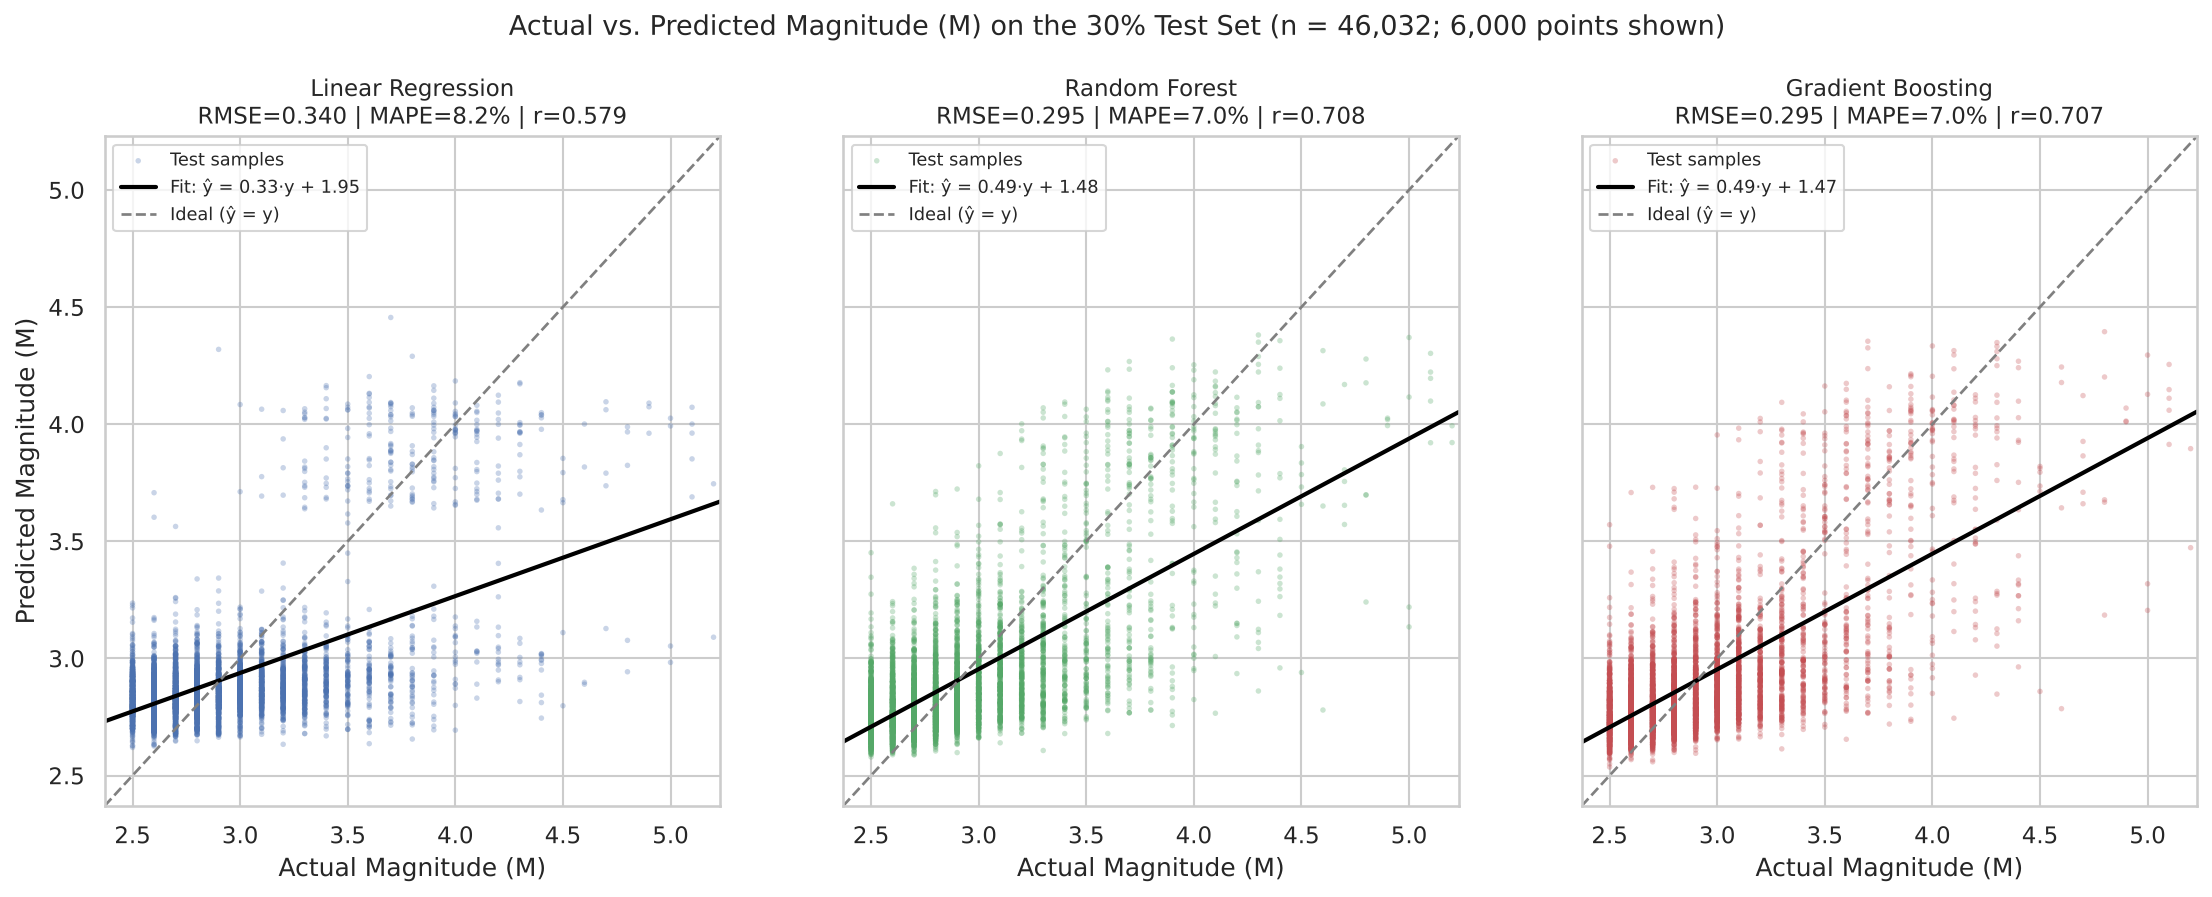

   Saved fig18_regression_magnitude_actual_vs_predicted.png


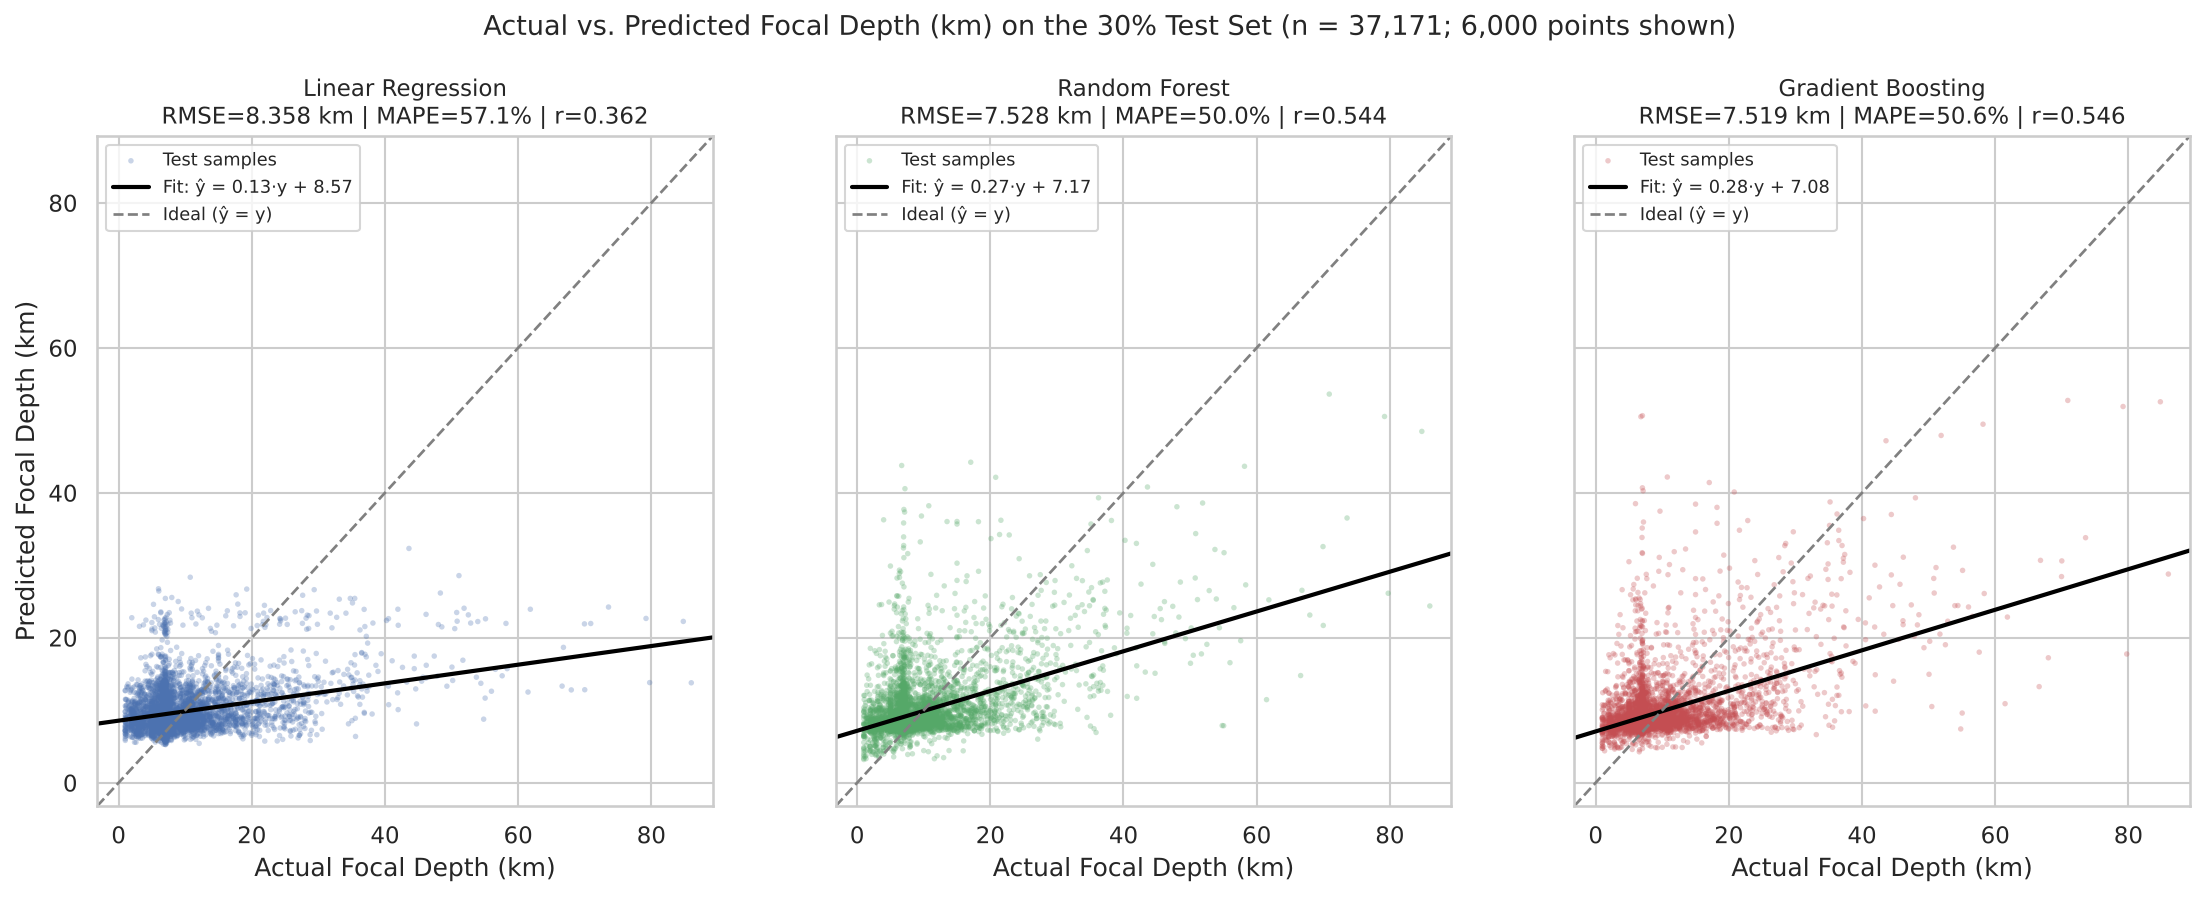

   Saved fig19_regression_depth_actual_vs_predicted.png


In [4]:
rng = np.random.default_rng(RANDOM_STATE)


def actual_vs_predicted_figure(target, fig_num):
    cfg = TARGET_CONFIG[target]
    s = store[target]
    y_test = s["y_test"]
    idx = rng.choice(len(y_test), size=min(PLOT_SAMPLE, len(y_test)), replace=False)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharex=True, sharey=True)
    lo, hi = np.percentile(y_test, [0.2, 99.8])
    pad = 0.05 * (hi - lo)
    lim = (lo - pad, hi + pad)
    for ax, (name, y_pred) in zip(axes, s["preds"].items()):
        ax.scatter(y_test[idx], y_pred[idx], s=7, alpha=0.30,
                   color=MODEL_COLORS[name], edgecolors="none", label="Test samples")
        # Least-squares regression line of predicted on actual (full test set)
        a, b = np.polyfit(y_test, y_pred, 1)
        xs = np.linspace(*lim, 100)
        ax.plot(xs, a * xs + b, color="black", lw=2.0, label=f"Fit: ŷ = {a:.2f}·y + {b:.2f}")
        ax.plot(lim, lim, ls="--", color="grey", lw=1.3, label="Ideal (ŷ = y)")
        m = results_summary["targets"][target]["test_metrics"][name]
        ax.set_title(f"{name}\nRMSE={m['RMSE']:.3f}{cfg['unit']} | "
                     f"MAPE={m['MAPE (%)']:.1f}% | r={m['Pearson r']:.3f}", fontsize=11)
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_xlabel(f"Actual {cfg['label']}")
        ax.legend(loc="upper left", fontsize=8.5, frameon=True)
    axes[0].set_ylabel(f"Predicted {cfg['label']}")
    fig.suptitle(f"Actual vs. Predicted {cfg['label']} on the 30% Test Set "
                 f"(n = {len(y_test):,}; {len(idx):,} points shown)", fontsize=13, y=1.02)
    path = os.path.join(FIG_DIR, f"fig{fig_num}_regression_{target}_actual_vs_predicted.png")
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"   Saved {os.path.basename(path)}")


print("\n3. Generating figures...")
actual_vs_predicted_figure("magnitude", 18)
actual_vs_predicted_figure("depth", 19)

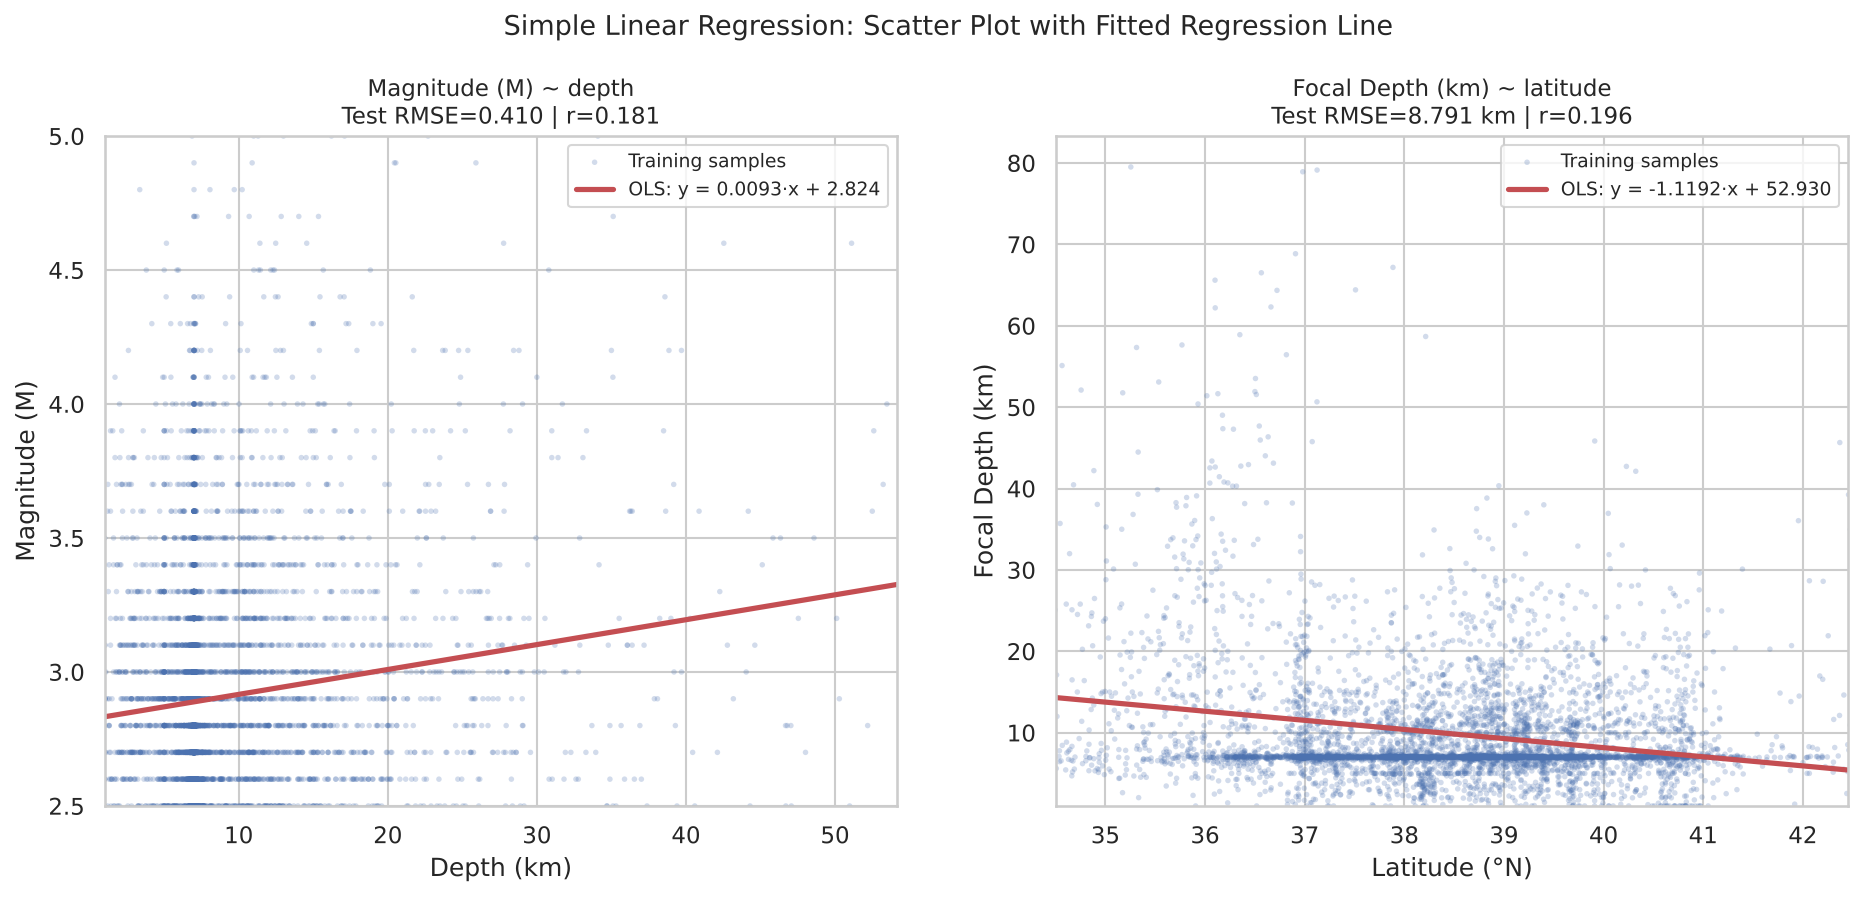

   Saved fig20_simple_linear_regression_lines.png


In [5]:
# Figure 20: simple linear regression lines (scatter with regression line on a single predictor)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, target in zip(axes, ["magnitude", "depth"]):
    cfg = TARGET_CONFIG[target]
    s = store[target]
    sf, slope, intercept = s["simple"]
    Xtr, ytr = s["X_train_raw"][sf].values, s["y_train"]
    idx = rng.choice(len(ytr), size=min(PLOT_SAMPLE, len(ytr)), replace=False)
    ax.scatter(Xtr[idx], ytr[idx], s=7, alpha=0.25, color="#4C72B0", edgecolors="none",
               label="Training samples")
    xs = np.linspace(np.percentile(Xtr, 0.5), np.percentile(Xtr, 99.5), 100)
    ax.plot(xs, slope * xs + intercept, color="#C44E52", lw=2.5,
            label=f"OLS: y = {slope:.4f}·x + {intercept:.3f}")
    sm = results_summary["targets"][target]["simple_linear"]["test_metrics"]
    ax.set_title(f"{cfg['label']} ~ {sf}\nTest RMSE={sm['RMSE']:.3f}{cfg['unit']} | "
                 f"r={sm['Pearson r']:.3f}", fontsize=11)
    ax.set_xlabel(sf.capitalize() + (" (km)" if sf == "depth" else " (°N)" if sf == "latitude" else ""))
    ax.set_ylabel(cfg["label"])
    ax.set_ylim(np.percentile(ytr, 0.2), np.percentile(ytr, 99.8))
    ax.set_xlim(xs[0], xs[-1])
    ax.legend(loc="upper right", fontsize=9)
fig.suptitle("Simple Linear Regression: Scatter Plot with Fitted Regression Line", fontsize=13, y=1.02)
path = os.path.join(FIG_DIR, "fig20_simple_linear_regression_lines.png")
plt.savefig(path, bbox_inches="tight")
plt.show()
print(f"   Saved {os.path.basename(path)}")

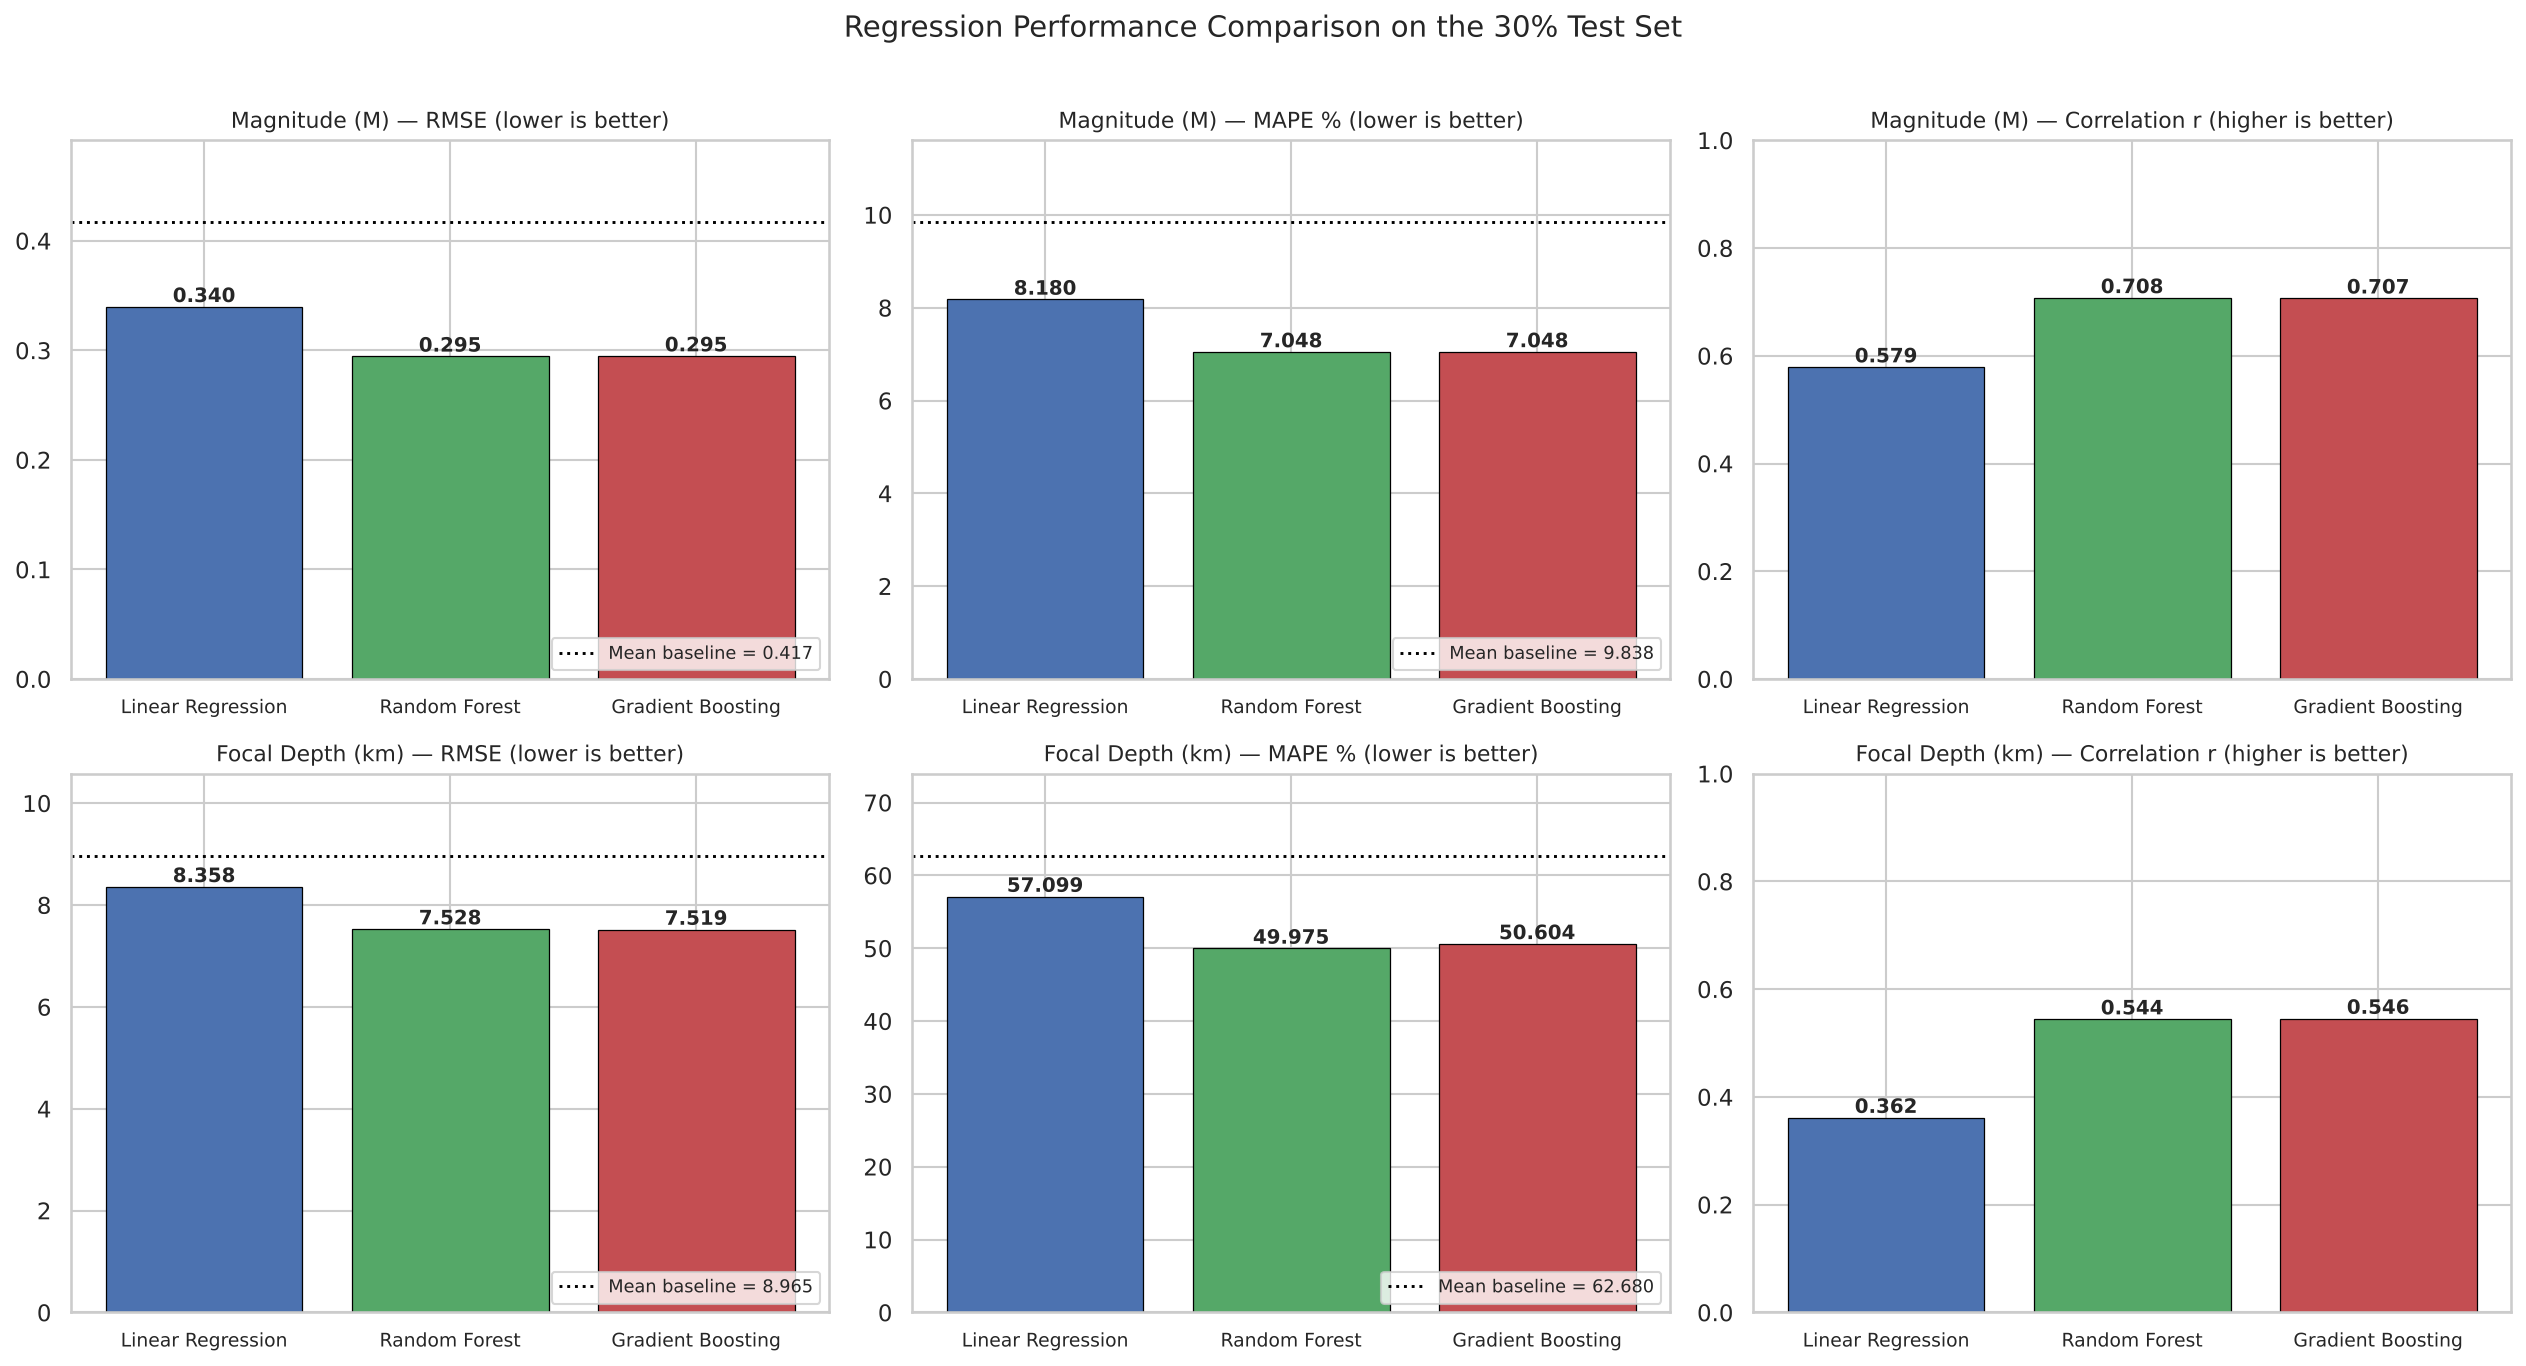

   Saved fig21_regression_metrics_comparison.png


In [6]:
# Figure 21: metric comparison (RMSE, MAPE, Pearson r) for both targets
metrics_to_plot = [("RMSE", "RMSE (lower is better)"),
                   ("MAPE (%)", "MAPE % (lower is better)"),
                   ("Pearson r", "Correlation r (higher is better)")]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for row, target in enumerate(["magnitude", "depth"]):
    tm = results_summary["targets"][target]["test_metrics"]
    names = list(tm.keys())
    for col, (mkey, mtitle) in enumerate(metrics_to_plot):
        ax = axes[row, col]
        vals = [tm[n][mkey] for n in names]
        bars = ax.bar(names, vals, color=[MODEL_COLORS[n] for n in names], edgecolor="black", lw=0.6)
        for b_, v in zip(bars, vals):
            ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height(), f"{v:.3f}",
                    ha="center", va="bottom", fontsize=9.5, fontweight="bold")
        if mkey in ("RMSE", "MAPE (%)"):
            base = results_summary["targets"][target]["baseline_mean_predictor"][mkey]
            ax.axhline(base, color="black", ls=":", lw=1.4, label=f"Mean baseline = {base:.3f}")
            ax.legend(fontsize=8.5, loc="lower right")
        if mkey == "Pearson r":
            ax.set_ylim(0, 1)
        else:
            ax.set_ylim(0, max(vals + [results_summary["targets"][target]["baseline_mean_predictor"][mkey]]) * 1.18)
        ax.set_title(f"{TARGET_CONFIG[target]['label']} — {mtitle}", fontsize=10.5)
        ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Regression Performance Comparison on the 30% Test Set", fontsize=14, y=1.01)
plt.tight_layout()
path = os.path.join(FIG_DIR, "fig21_regression_metrics_comparison.png")
plt.savefig(path, bbox_inches="tight")
plt.show()
print(f"   Saved {os.path.basename(path)}")

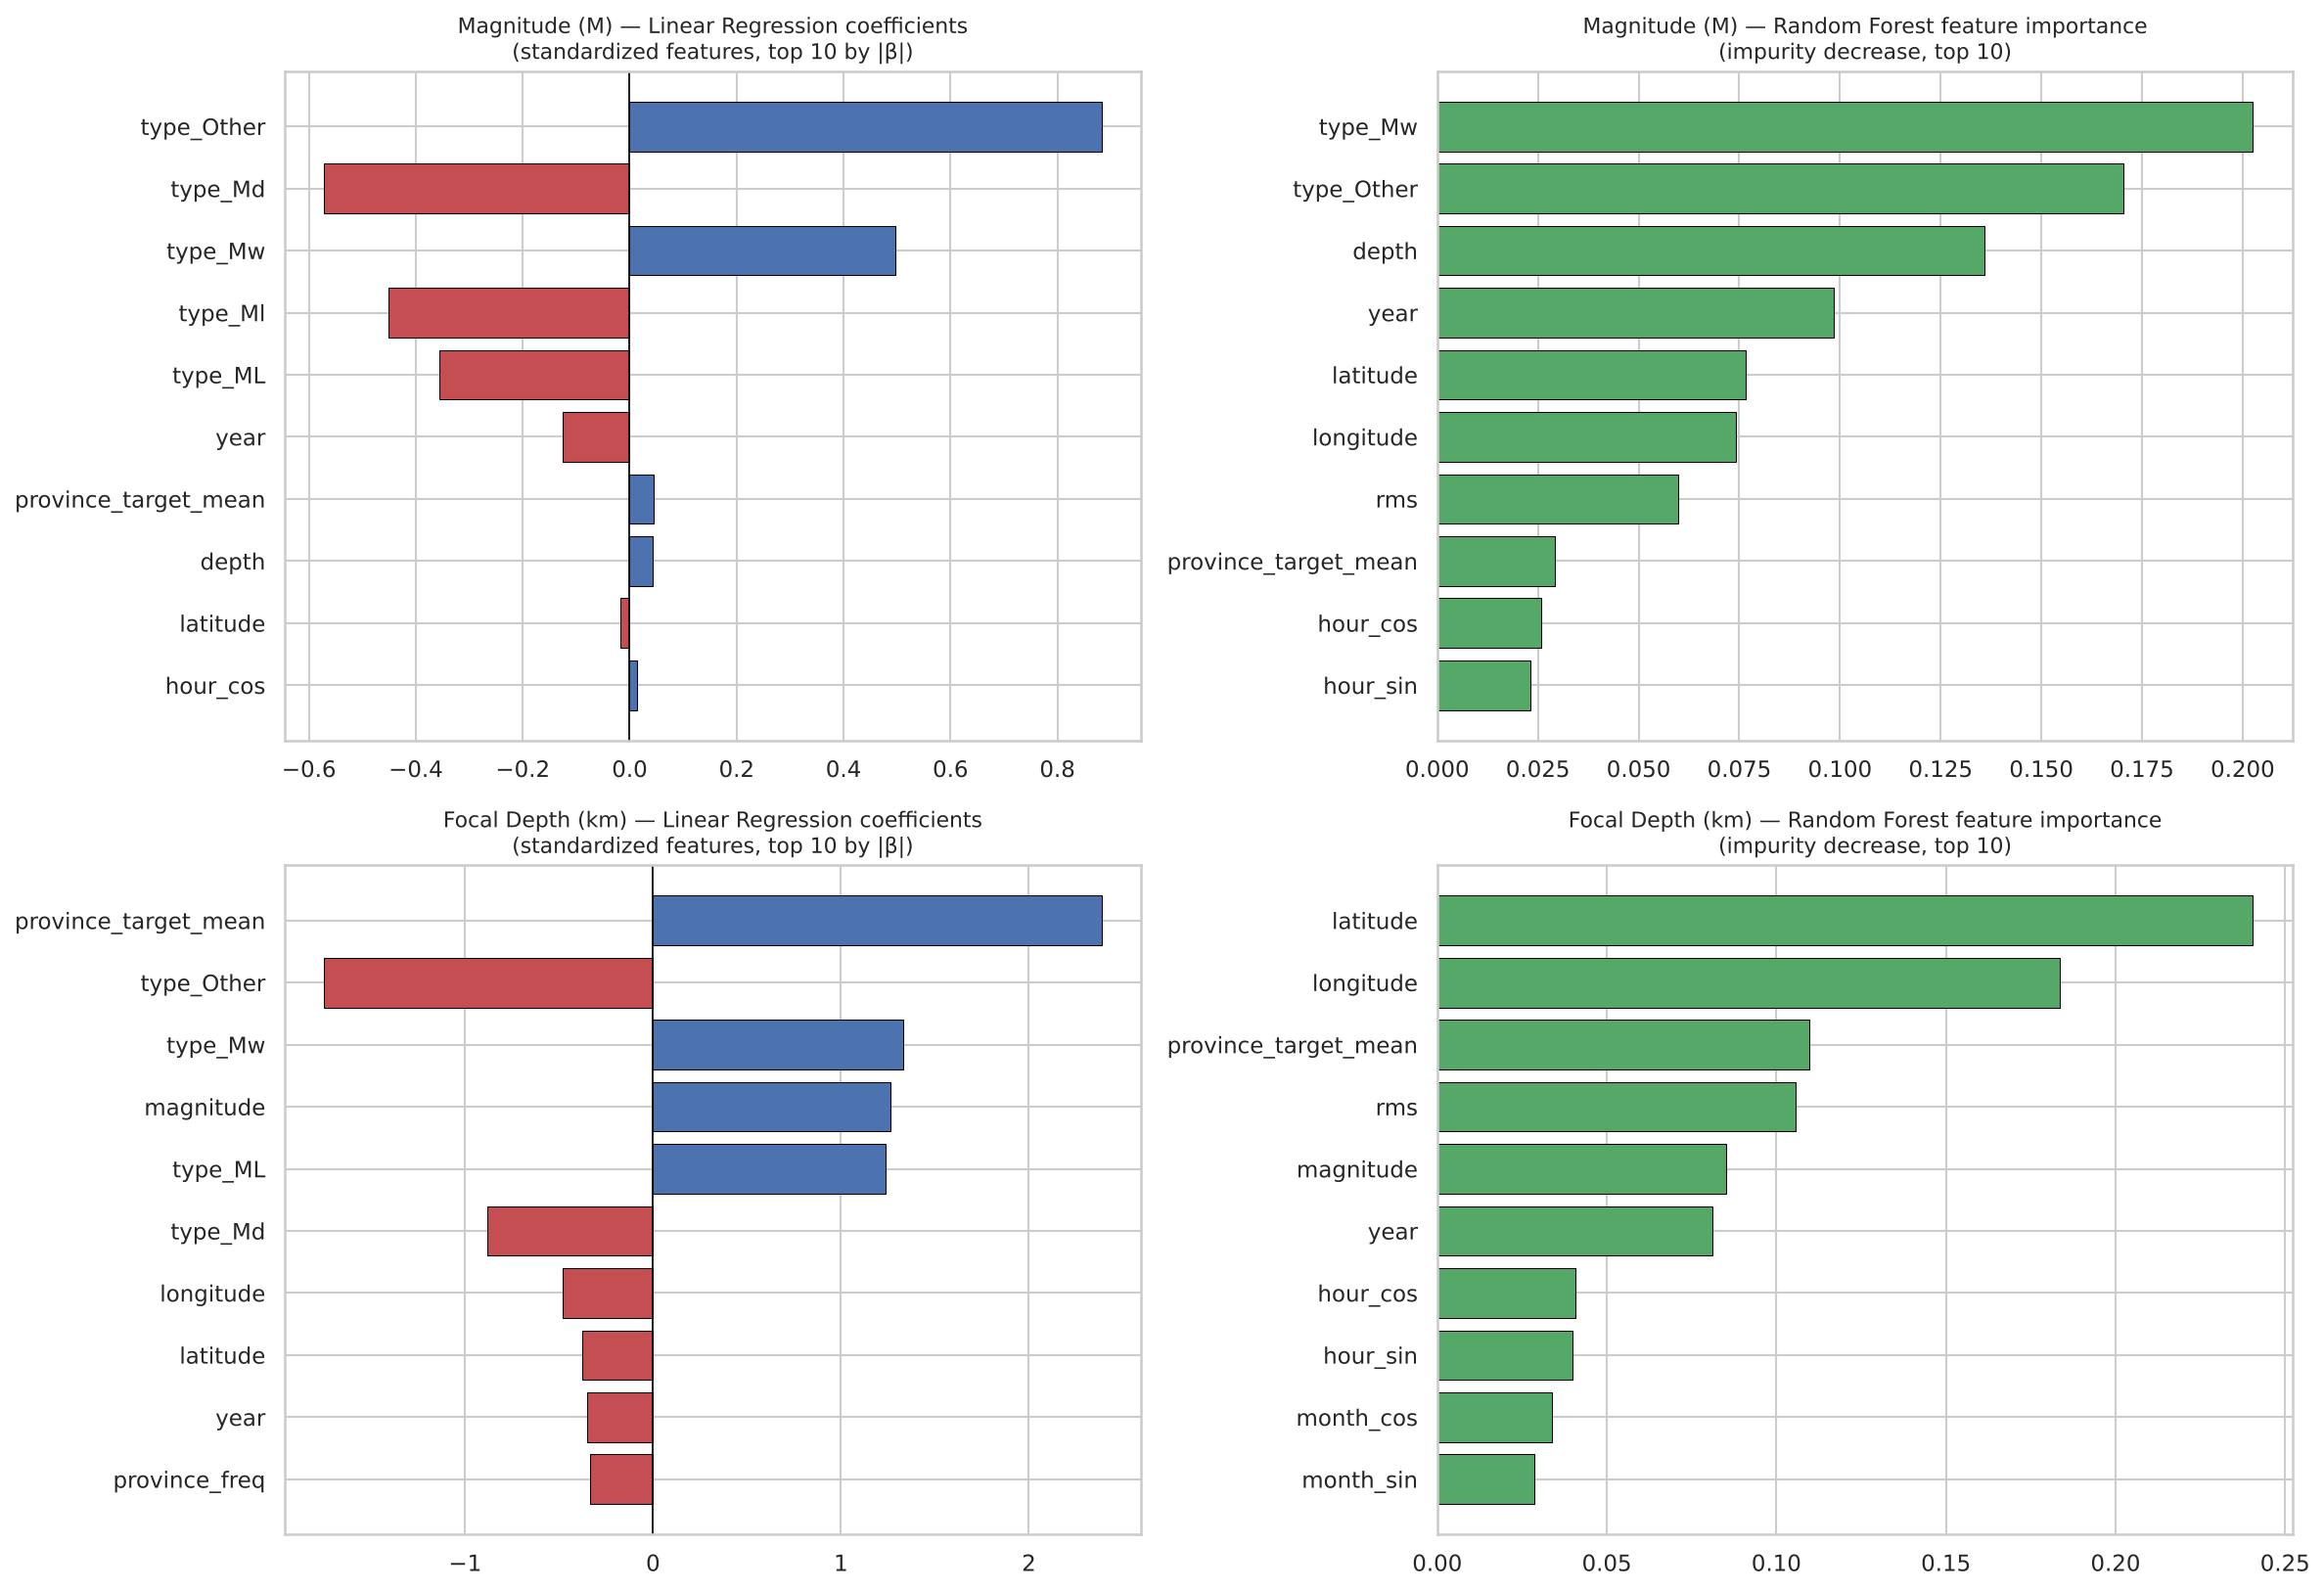

   Saved fig22_regression_coefficients_and_importance.png


In [7]:
# Figure 22: learned model internals — LR standardized coefficients & RF feature importance
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for row, target in enumerate(["magnitude", "depth"]):
    tr = results_summary["targets"][target]
    coefs = pd.Series(tr["linear_coefficients_standardized"]).head(10)[::-1]
    axes[row, 0].barh(coefs.index, coefs.values,
                      color=["#C44E52" if v < 0 else "#4C72B0" for v in coefs.values], edgecolor="black", lw=0.5)
    axes[row, 0].axvline(0, color="black", lw=0.8)
    axes[row, 0].set_title(f"{TARGET_CONFIG[target]['label']} — Linear Regression coefficients\n"
                           "(standardized features, top 10 by |β|)", fontsize=10.5)
    imp = pd.Series(tr["rf_feature_importance"]).head(10)[::-1]
    axes[row, 1].barh(imp.index, imp.values, color="#55A868", edgecolor="black", lw=0.5)
    axes[row, 1].set_title(f"{TARGET_CONFIG[target]['label']} — Random Forest feature importance\n"
                           "(impurity decrease, top 10)", fontsize=10.5)
plt.tight_layout()
path = os.path.join(FIG_DIR, "fig22_regression_coefficients_and_importance.png")
plt.savefig(path, bbox_inches="tight")
plt.show()
print(f"   Saved {os.path.basename(path)}")

## 5. Results Summary

In [8]:
print("\n4. Test-set summary")
rows = []
for target, tr in results_summary["targets"].items():
    for name, m in tr["test_metrics"].items():
        rows.append({"Target": target, "Model": name, **{k: round(v, 4) for k, v in m.items()}})
    b = tr["baseline_mean_predictor"]
    rows.append({"Target": target, "Model": "Mean baseline",
                 "RMSE": round(b["RMSE"], 4), "MAE": round(b["MAE"], 4), "MAPE (%)": round(b["MAPE (%)"], 4)})
summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

print("\nTrain vs. test RMSE (overfitting check)")
for target, tr in results_summary["targets"].items():
    for name in tr["test_metrics"]:
        print(f"  {target:9s} {name:18s} train={tr['train_metrics'][name]['RMSE']:.4f} "
              f"test={tr['test_metrics'][name]['RMSE']:.4f}")

print("\nResults JSON:")
print(json.dumps({t: {"test_metrics": v["test_metrics"],
                      "simple_linear": v["simple_linear"],
                      "baseline_mean_predictor": v["baseline_mean_predictor"]}
                  for t, v in results_summary["targets"].items()}, indent=2))
print("\nDone.")


4. Test-set summary
   Target             Model   RMSE    MAE  MAPE (%)  Pearson r     R2
magnitude Linear Regression 0.3398 0.2465    8.1797     0.5791 0.3351
magnitude     Random Forest 0.2945 0.2120    7.0476     0.7076 0.5005
magnitude Gradient Boosting 0.2948 0.2121    7.0483     0.7068 0.4995
magnitude     Mean baseline 0.4167 0.3001    9.8376        NaN    NaN
    depth Linear Regression 8.3584 4.4316   57.0993     0.3617 0.1307
    depth     Random Forest 7.5283 3.8672   49.9749     0.5445 0.2948
    depth Gradient Boosting 7.5190 3.9150   50.6039     0.5456 0.2965
    depth     Mean baseline 8.9649 4.8732   62.6799        NaN    NaN

Train vs. test RMSE (overfitting check)
  magnitude Linear Regression  train=0.3382 test=0.3398
  magnitude Random Forest      train=0.2314 test=0.2945
  magnitude Gradient Boosting  train=0.2754 test=0.2948
  depth     Linear Regression  train=8.1129 test=8.3584
  depth     Random Forest      train=5.6466 test=7.5283
  depth     Gradient Boostin

## 6. Discussion

**Test-set results (30% hold-out):**

| Target | Model | RMSE | MAPE (%) | Pearson r | $R^2$ |
|---|---|---|---|---|---|
| Magnitude | Mean baseline | 0.417 | 9.84 | – | – |
| Magnitude | Linear Regression | 0.340 | 8.18 | 0.579 | 0.335 |
| Magnitude | Random Forest | **0.295** | **7.05** | **0.708** | **0.501** |
| Magnitude | Gradient Boosting | 0.295 | 7.05 | 0.707 | 0.500 |
| Depth (km) | Mean baseline | 8.965 | 62.68 | – | – |
| Depth (km) | Linear Regression | 8.358 | 57.10 | 0.362 | 0.131 |
| Depth (km) | Random Forest | 7.528 | **49.97** | 0.544 | 0.295 |
| Depth (km) | Gradient Boosting | **7.519** | 50.60 | **0.546** | **0.297** |

**1. Non-linear ensembles clearly outperform the linear model.** For both targets, Random Forest and Gradient Boosting reduce RMSE by about 13% (magnitude) and 10% (depth) compared to Linear Regression, and raise the correlation from 0.58 → 0.71 and 0.36 → 0.55. The two ensembles are practically tied (differences in the third decimal), which suggests the remaining error is caused by the information content of the features rather than by the choice of tree ensemble.

**2. Why the linear model is limited.** Seismic behaviour depends on *where* an event happens (fault zone, subduction slab) in a strongly non-linear way. A single linear plane over latitude/longitude cannot represent such localized patterns, whereas trees split the map into regions. The simple univariate fits in Fig. 20 show this clearly: depth alone explains very little of magnitude ($r=0.18$), and latitude alone explains very little of depth ($r=0.20$).

**3. Magnitude is predictable mainly through the measurement method.** Both the Linear Regression coefficients and the Random Forest importances (Fig. 22) are dominated by the `type` one-hot columns. Moment magnitude (Mw; the `type_Other` group consists almost entirely of upper-case "MW" labels) is computed by AFAD mostly for larger events (mean M ≈ 3.8–4.1 vs. ≈ 2.85 for ML/Md), so these columns act as an indirect indicator of a larger magnitude. This is a catalogue-procedure effect, not a physical precursor, so the model should be interpreted as *estimating* magnitude from catalogue metadata, not as *forecasting* earthquakes.

**4. Regression toward the mean.** In Fig. 18 and Fig. 19 the fitted lines are flatter than the ideal $\hat{y}=y$ line (slope ≈ 0.49 for magnitude, ≈ 0.28 for depth). Large magnitudes and deep events are systematically under-estimated, because they are rare (Gutenberg–Richter distribution) and squared-error training favours the dense region around M ≈ 2.5–3.0 and depth ≈ 5–15 km. This is the regression counterpart of the class imbalance observed in the classification task.

**5. Depth is the harder target, and MAPE exaggerates the difficulty.** Depth MAPE is around 50% while RMSE is around 7.5 km. Most depths are small (median ≈ 7 km, IQR 6.9–10.4 km), so a 4 km absolute error on a 3 km event becomes a >100% percentage error. RMSE and correlation are therefore more meaningful for depth than MAPE. The 7.00 km fixed-depth rows (~19% of the catalogue) were removed; keeping them would have rewarded models for predicting a constant default value instead of physical depth.

**6. Overfitting check.** Random Forest has the largest train–test gap (magnitude RMSE 0.231 → 0.295; depth 5.65 → 7.53), while Gradient Boosting is more balanced (0.275 → 0.295; 6.51 → 7.52) with nearly identical test scores. Gradient Boosting is therefore the preferred model: equal accuracy with better generalization and faster training.

**Conclusion.** Both numeric targets are learnable above the mean baseline, but only partially ($R^2 \approx 0.50$ for magnitude and $\approx 0.30$ for depth). Better results would require physics-based features such as distance to the nearest mapped fault, time since the last large mainshock (Omori–Utsu decay), or local event density.
